# When to Go, Not Just Where: NYC Itinerary Planning (Phase 1)

This notebook has two parts:
- **Part 1: Data preprocessing (10 steps)**: clean the three datasets.
- **Part 2: Exploratory data analysis (10 steps)**: look for patterns that help plan a trip.

**Datasets**
1. **Foursquare NYC check-ins** (2012–2013): who visited which place, and when.
2. **Google Local places, New York**: place names, categories, ratings and prices.
3. **Brooklyn Bridge pedestrian counts** (2017–2019): people crossing per hour, with weather.

---
# Part 1: Data Preprocessing (10 steps)

### Step 1: Load the data, keep useful columns, rename them, and fix data types
**Why:** we first read the three raw files. The datasets have columns we will not use (for example Google's `url` and `MISC`) and
inconsistent names (`Towards Manhattan`, `Pedestrians`). Using the same simple naming style
everywhere makes the code easier to read. IDs should be text, not numbers.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

RAW = "../data/raw/"
OUT = "../data/processed/"
FIG = "../figures/"

fs_columns = ["user_id", "venue_id", "venue_category_id", "venue_category",
              "latitude", "longitude", "timezone_offset", "utc_time"]
fs = pd.read_csv(RAW + "dataset_TSMC2014_NYC.txt", sep="	", header=None,
                 names=fs_columns, encoding="latin-1")                        # no header row
google = pd.read_json(RAW + "meta-New_York.json.gz", lines=True)             # one JSON per line
bridge = pd.read_csv(RAW + "Brooklyn_Bridge_Automated_Pedestrian_Counts.csv")
print("Raw sizes:", fs.shape, google.shape, bridge.shape)

# Google: keep only the columns we need
google = google[["gmap_id", "name", "latitude", "longitude", "category",
                 "avg_rating", "num_of_reviews", "price", "state"]]

# Bridge: rename columns to lower_case_with_underscores
bridge = bridge.rename(columns={
    "Pedestrians": "pedestrians",
    "Towards Manhattan": "towards_manhattan",
    "Towards Brooklyn": "towards_brooklyn",
})
bridge = bridge.drop(columns=["location", "lat", "long", "Location1"])  # same value in every row

# IDs should be text
fs["user_id"] = fs["user_id"].astype(str)
fs["venue_id"] = fs["venue_id"].astype(str)

print("Foursquare columns:", list(fs.columns))
print("Google columns:    ", list(google.columns))
print("Bridge columns:    ", list(bridge.columns))

FileNotFoundError: [Errno 2] No such file or directory: '../data/raw/dataset_TSMC2014_NYC.txt'

### Step 2: Remove duplicate rows
**Why:** duplicate rows count the same visit twice, which makes places look more popular than they are.
In Google, the same place (`gmap_id`) can appear more than once.

In [2]:
print("Before:", len(fs), len(google), len(bridge))

fs = fs.drop_duplicates()
google = google.drop_duplicates(subset="gmap_id")
bridge = bridge.drop_duplicates()

print("After: ", len(fs), len(google), len(bridge))

Before: 227428 272189 16057
After:  227178 270720 16057


### Step 3: Convert timestamps to New York local time
**Why:** Foursquare stores time in UTC (London time), e.g. `Tue Apr 03 18:00:09 +0000 2012`.
To answer "what time do people visit?" we need **local** time. The `timezone_offset` column
tells us how many minutes to add. The bridge times are text like `04/30/2019 12:00:00 AM`,
so we convert them to real datetime values.

In [3]:
# Foursquare: text -> UTC datetime -> add the offset (in minutes) to get local time
fs["utc_time"] = pd.to_datetime(fs["utc_time"], format="%a %b %d %H:%M:%S %z %Y")
fs["local_time"] = fs["utc_time"].dt.tz_localize(None) + pd.to_timedelta(fs["timezone_offset"], unit="m")
fs = fs.drop(columns=["utc_time", "timezone_offset"])

# Bridge: text -> datetime, then sort by time
bridge["hour_beginning"] = pd.to_datetime(bridge["hour_beginning"], format="%m/%d/%Y %I:%M:%S %p")
bridge = bridge.sort_values("hour_beginning").reset_index(drop=True)

print(fs[["venue_category", "local_time"]].head())
print("Bridge data covers", bridge["hour_beginning"].min(), "to", bridge["hour_beginning"].max())

        venue_category          local_time
0  Arts & Crafts Store 2012-04-03 14:00:09
1               Bridge 2012-04-03 14:00:25
2       Home (private) 2012-04-03 14:02:24
3       Medical Center 2012-04-03 14:02:41
4           Food Truck 2012-04-03 14:03:00
Bridge data covers 2017-10-01 00:00:00 to 2019-12-31 23:00:00


### Step 4: Handle missing values
**Why:** missing values can break calculations or give wrong averages. Each column needs its own fix:
- **Bridge weather, temperature, precipitation** (only 16 rows missing): copy the value from the previous hour
  (weather does not change much in one hour).
- **Bridge events** (mostly empty because most days are not holidays): turn it into a yes/no column `has_event`.
- **Google category** or **coordinates** missing: drop the row (we cannot place it on a map or give it a theme).
- **Google price** missing: leave it empty. We don't know the price, and guessing would be wrong.

In [4]:
print("Missing values BEFORE:")
print("Foursquare:", fs.isna().sum().sum())
print(google.isna().sum(), "\n")
print(bridge.isna().sum(), "\n")

# Bridge
bridge[["weather_summary", "temperature", "precipitation"]] = bridge[["weather_summary", "temperature", "precipitation"]].ffill()
bridge["has_event"] = bridge["events"].notna()
bridge = bridge.drop(columns=["events"])

# Google
google = google.dropna(subset=["category", "latitude", "longitude"])

print("Missing values AFTER (bridge):", bridge.isna().sum().sum())
print("Google rows left:", len(google))

Missing values BEFORE:
Foursquare: 0
gmap_id                0
name                   2
latitude               0
longitude              0
category            1002
avg_rating             0
num_of_reviews         0
price             212199
state              76844
dtype: int64 

hour_beginning           0
pedestrians              0
towards_manhattan        0
towards_brooklyn         0
weather_summary         16
temperature             16
precipitation           16
events               14933
dtype: int64 

Missing values AFTER (bridge): 0
Google rows left: 269718


### Step 5: Remove invalid rows (outside NYC, or closed places)
**Why:**
- The Google file covers **all of New York State**, and some Foursquare points have bad GPS.
  We keep only points inside a box around New York City.
- Google places marked **"Permanently closed"** or **"Temporarily closed"** should never be recommended.

In [5]:
# NYC bounding box (the five boroughs)
LAT_MIN, LAT_MAX = 40.48, 40.92
LON_MIN, LON_MAX = -74.26, -73.70

def inside_nyc(df):
    return df["latitude"].between(LAT_MIN, LAT_MAX) & df["longitude"].between(LON_MIN, LON_MAX)

print("Before:", len(fs), len(google))
fs = fs[inside_nyc(fs)]
google = google[inside_nyc(google)]

# Remove closed places
closed = google["state"].str.contains("Permanently closed|Temporarily closed", na=False)
print("Closed Google places removed:", closed.sum())
google = google[~closed].drop(columns=["state"])

print("After: ", len(fs), len(google))

Before: 227178 269718
Closed Google places removed: 12872
After:  219076 102216


### Step 6: Clean text labels
**Why:** the same thing is sometimes written in different ways, which splits one group into two.
- Bridge weather has labels like `clear-day` and `clear-night`. The time of day is already in the timestamp,
  so we merge them into just `clear`.
- Some Google prices use the Korean won sign (`₩₩`) instead of `$$`. They mean the same price level.
- Remove extra spaces from category names.

In [6]:
print("Weather labels before:")
print(bridge["weather_summary"].value_counts(), "\n")
bridge["weather_summary"] = bridge["weather_summary"].str.replace("-day", "").str.replace("-night", "")
print("Weather labels after:")
print(bridge["weather_summary"].value_counts(), "\n")

google["price"] = google["price"].str.replace("₩", "$")
print("Price labels after:")
print(google["price"].value_counts())

fs["venue_category"] = fs["venue_category"].str.strip()

Weather labels before:
weather_summary
clear-night            3755
partly-cloudy-day      3169
clear-day              3127
partly-cloudy-night    2508
cloudy                 2383
rain                    920
snow                     93
fog                      76
sleet                    14
wind                     12
Name: count, dtype: int64 

Weather labels after:
weather_summary
clear            6882
partly-cloudy    5677
cloudy           2383
rain              920
snow               93
fog                76
sleet              14
wind               12
Name: count, dtype: int64 

Price labels after:
price
$$      11287
$       10188
$$$      1391
$$$$      370
Name: count, dtype: int64


### Step 7: Group categories into travel themes
**Why:** Foursquare has about 250 categories and Google has thousands. Many are not useful for a tourist
(`Home (private)`, `Office`, `Subway`, `Gym`). We:
1. **remove** non-travel categories, and
2. **group** the rest into 7 themes: Museums & Arts, Food & Drink, Nightlife, Landmarks & Views,
   Parks & Outdoors, Entertainment, Shopping.

We split the category name into words and look for keywords. The order matters: "Sushi Bar" is checked for
food words before nightlife words, so it becomes Food & Drink.

In [7]:
# Categories that contain any of these words are removed (not useful for a tourist)
NOT_TRAVEL = """
    home office residential building subway station bus train road highway parking car gas automotive
    bank atm laundry laundromat pharmacy drugstore grocery supermarket convenience hardware medical
    doctor dentist hospital gym fitness school college university student government salon barbershop
    spa church temple synagogue mosque hotel motel hostel airport police insurance lawyer storage
    cemetery factory coworking startup daycare
""".split()

# Keywords for each theme. The themes are checked from top to bottom.
THEMES = {
    "Museums & Arts":    "museum gallery aquarium planetarium exhibit",
    "Food & Drink":      "restaurant café cafe coffee bakery pizza burger deli dessert diner sandwich food tea donut "
                         "bagel cream sushi steakhouse bistro breakfast snack taco noodle bbq juice salad cupcake "
                         "yogurt dumpling ramen bodega",
    "Nightlife":         "bar pub lounge nightclub brewery beer wine cocktail karaoke speakeasy nightlife",
    "Landmarks & Views": "monument landmark bridge plaza scenic memorial harbor pier ferry historic sculpture "
                         "tourist observation marina",
    "Parks & Outdoors":  "park garden beach playground trail zoo outdoors river lake",
    "Entertainment":     "theater theatre stadium arena concert music comedy cinema movie bowling arcade casino "
                         "performing",
    "Shopping":          "mall market boutique clothing shoe book bookstore department gift toy jewelry electronics "
                         "apparel thrift flea shopping souvenir cosmetics",
}

def get_theme(category):
    """Return the travel theme of a category name, or None if it is not useful for travel."""
    if not isinstance(category, str):
        return None
    for symbol in "/&()":
        category = category.replace(symbol, " ")
    words = category.lower().split()
    if any(word in NOT_TRAVEL for word in words):
        return None
    for theme, keywords in THEMES.items():
        if any(word in keywords.split() for word in words):
            return theme
    return None

# Foursquare: one category per row
fs["theme"] = fs["venue_category"].apply(get_theme)

# Google: category is a list, e.g. ["Italian restaurant", "Pizza restaurant"]; use the first one
google["main_category"] = google["category"].str[0]
google["theme"] = google["main_category"].apply(get_theme)
google = google.drop(columns=["category"])

print("Most common categories we are dropping (check nothing important is lost):")
print(fs.loc[fs["theme"].isna(), "venue_category"].value_counts().head(10), "\n")

print("Before:", len(fs), len(google))
fs = fs.dropna(subset=["theme"])
google = google.dropna(subset=["theme"])
print("After: ", len(fs), len(google))
fs["theme"].value_counts()

Most common categories we are dropping (check nothing important is lost):
venue_category
Home (private)                              14269
Office                                      12515
Subway                                       9337
Gym / Fitness Center                         8620
Train Station                                6208
Neighborhood                                 4552
Bus Station                                  4385
Residential Building (Apartment / Condo)     4102
College Academic Building                    3371
Building                                     3335
Name: count, dtype: int64 

Before: 219076 102216
After:  104091 36888


theme
Food & Drink         54616
Nightlife            16469
Parks & Outdoors     10339
Shopping              9178
Entertainment         7191
Landmarks & Views     5133
Museums & Arts        1165
Name: count, dtype: int64

### Step 8: Convert text columns into numbers
**Why:** we cannot do math on text.
- Google `price` is text like `$$`, so we turn it into a number from 1 to 4 (`price_level`) by counting the `$` signs.
- Foursquare `venue_category_id` repeats the same information as `venue_category`, so we drop it.

In [8]:
google["price_level"] = google["price"].str.len()   # "$" -> 1, "$$" -> 2, missing stays missing
google = google.drop(columns=["price"])
fs = fs.drop(columns=["venue_category_id"])

print(google["price_level"].value_counts(dropna=False))

price_level
NaN    17599
1.0     9105
2.0     8901
3.0     1024
4.0      259
Name: count, dtype: int64


### Step 9: Remove users and places with very few check-ins
**Why:** a user with only 1–2 check-ins tells us almost nothing about their habits, and a place visited only
once or twice does not have a reliable "best time to visit". We keep users with **at least 5** check-ins and
places with **at least 3**.

(Removing rare places can push a few users slightly below 5 check-ins. That is fine for our analysis.)

In [9]:
MIN_USER = 5
MIN_VENUE = 3

print("Before:", len(fs), "check-ins")

user_counts = fs["user_id"].value_counts()
venue_counts = fs["venue_id"].value_counts()
good_users = user_counts[user_counts >= MIN_USER].index
good_venues = venue_counts[venue_counts >= MIN_VENUE].index

fs = fs[fs["user_id"].isin(good_users) & fs["venue_id"].isin(good_venues)]

print("After: ", len(fs), "check-ins")
print("Users:", fs["user_id"].nunique(), " Venues:", fs["venue_id"].nunique())

Before: 104091 check-ins
After:  89118 check-ins
Users: 1078  Venues: 8645


### Step 10: Create new time features (feature engineering)
**Why:** our project is about **when** to visit, so we create columns that describe the time:
`hour`, `day_of_week`, `is_weekend`, `month`, `season`, and `light_period`.

For `light_period` we use the **average sunset time in NYC for each month** (for example, about 8:30 PM in June
and 4:30 PM in December) and label each visit as:
- **Golden hour**: up to 1.5 hours before sunset (best light for photos)
- **Dusk**: up to 1 hour after sunset
- **Night**: later than that, or before 6 AM
- **Day**: everything else

At the end we save the three cleaned tables to `data/processed/`.

In [10]:
# Average NYC sunset time for each month, in hours (20.5 = 8:30 PM), daylight saving included
SUNSET_HOUR = {1: 16.9, 2: 17.6, 3: 19.1, 4: 19.7, 5: 20.2, 6: 20.5,
               7: 20.4, 8: 19.9, 9: 19.1, 10: 18.3, 11: 16.7, 12: 16.5}

SEASON = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
          6: "Summer", 7: "Summer", 8: "Summer", 9: "Fall", 10: "Fall", 11: "Fall"}

def get_light_period(hours_to_sunset, hour):
    if hour < 6:
        return "Night"
    if 0 < hours_to_sunset <= 1.5:
        return "Golden hour"
    if -1 < hours_to_sunset <= 0:
        return "Dusk"
    if hours_to_sunset <= -1:
        return "Night"
    return "Day"

def add_time_features(df, time_column):
    t = df[time_column]
    df["hour"] = t.dt.hour
    df["day_of_week"] = t.dt.day_name()
    df["is_weekend"] = t.dt.dayofweek >= 5          # Saturday = 5, Sunday = 6
    df["month"] = t.dt.month
    df["season"] = df["month"].map(SEASON)
    time_in_hours = t.dt.hour + t.dt.minute / 60
    df["hours_to_sunset"] = (df["month"].map(SUNSET_HOUR) - time_in_hours).round(2)
    df["light_period"] = [get_light_period(h, hr) for h, hr in zip(df["hours_to_sunset"], df["hour"])]
    return df

fs = add_time_features(fs, "local_time")
bridge = add_time_features(bridge, "hour_beginning")

print(fs[["local_time", "theme", "hour", "day_of_week", "is_weekend", "season", "light_period"]].head())

# Save the cleaned data
fs.to_csv(OUT + "foursquare_checkins_clean.csv", index=False)
google.to_csv(OUT + "google_places_clean.csv", index=False)
bridge.to_csv(OUT + "brooklyn_bridge_clean.csv", index=False)

print("Final sizes:")
print("Foursquare:", fs.shape)
print("Google:    ", google.shape)
print("Bridge:    ", bridge.shape)

            local_time              theme  hour day_of_week  is_weekend  \
1  2012-04-03 14:00:25  Landmarks & Views    14     Tuesday       False   
4  2012-04-03 14:03:00       Food & Drink    14     Tuesday       False   
5  2012-04-03 14:04:00       Food & Drink    14     Tuesday       False   
6  2012-04-03 14:04:38       Food & Drink    14     Tuesday       False   
11 2012-04-03 14:08:57           Shopping    14     Tuesday       False   

    season light_period  
1   Spring          Day  
4   Spring          Day  
5   Spring          Day  
6   Spring          Day  
11  Spring          Day  
Final sizes:
Foursquare: (89118, 14)
Google:     (36888, 9)
Bridge:     (16057, 15)


---
# Part 2: Exploratory Data Analysis (10 steps)

### EDA 1: Summary statistics
Mean, median, standard deviation, min and max of the main numeric columns, and how many check-ins
each theme has.

In [11]:
checkins_per_user = fs["user_id"].value_counts()
checkins_per_venue = fs["venue_id"].value_counts()

summary = pd.DataFrame({
    "check-ins per user": checkins_per_user.describe(),
    "check-ins per venue": checkins_per_venue.describe(),
    "bridge pedestrians/hour": bridge["pedestrians"].describe(),
    "bridge temperature (F)": bridge["temperature"].describe(),
    "google rating": google["avg_rating"].describe(),
    "google # reviews": google["num_of_reviews"].describe(),
})
print(summary.round(2))
print()

theme_table = pd.DataFrame({
    "check-ins": fs["theme"].value_counts(),
    "percent": (fs["theme"].value_counts(normalize=True) * 100).round(1),
    "google places": google["theme"].value_counts(),
})
print(theme_table)

       check-ins per user  check-ins per venue  bridge pedestrians/hour  \
count             1078.00              8645.00                 16057.00   
mean                82.67                10.31                   687.11   
std                 72.82                16.89                   862.24   
min                  3.00                 3.00                     0.00   
25%                 45.00                 4.00                    16.00   
50%                 67.00                 6.00                   227.00   
75%                 95.75                10.00                  1254.00   
max               1013.00               472.00                  4330.00   

       bridge temperature (F)  google rating  google # reviews  
count                16057.00       36888.00          36888.00  
mean                    53.21           4.24            274.56  
std                     18.04           0.46            648.52  
min                      2.00           1.00              1.00  

**What we learned:** For check-ins per user, check-ins per venue and Google reviews, the **mean is much bigger than the median**
(e.g. 10.3 vs 6 check-ins per venue). This means a few very popular places pull the average up, so the median is a
better "typical" value. Food & Drink has about half of all check-ins (51%), while Museums & Arts has less than 1%.

**How we use it:** use medians to describe typical values, and don't let raw popularity alone decide recommendations.

### EDA 2: How popular are places? (distribution of check-ins)
Histograms of check-ins per user and per venue.

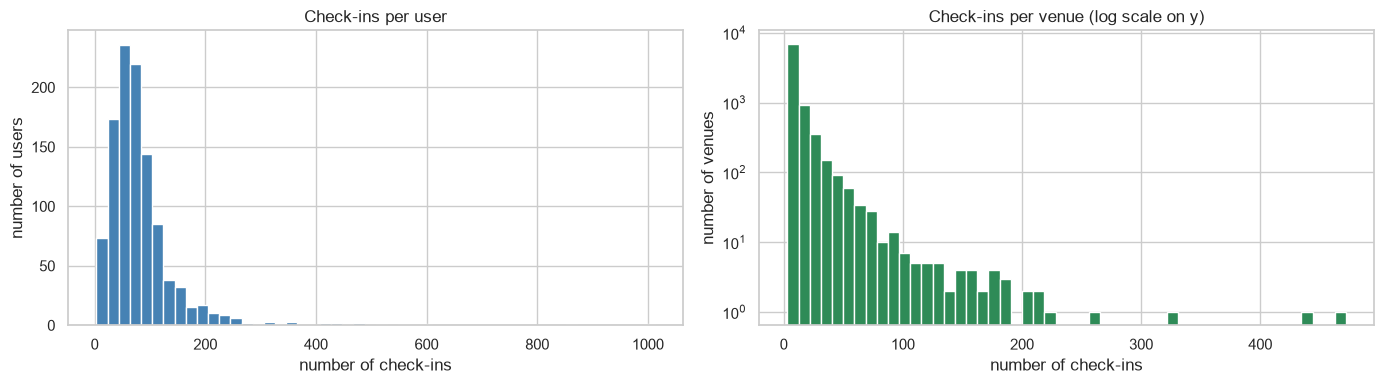

The top 10% of venues get 42% of all check-ins


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(checkins_per_user, bins=50, color="steelblue")
axes[0].set_title("Check-ins per user")
axes[0].set_xlabel("number of check-ins")
axes[0].set_ylabel("number of users")

axes[1].hist(checkins_per_venue, bins=50, color="seagreen", log=True)
axes[1].set_title("Check-ins per venue (log scale on y)")
axes[1].set_xlabel("number of check-ins")
axes[1].set_ylabel("number of venues")

plt.tight_layout()
plt.savefig(FIG + "eda02_popularity.png", dpi=150)
plt.show()

top_10_percent = checkins_per_venue.head(len(checkins_per_venue) // 10).sum() / checkins_per_venue.sum()
print(f"The top 10% of venues get {top_10_percent:.0%} of all check-ins")

**What we learned:** Most venues have only a few check-ins, but a small number have hundreds. The **top 10% of venues get 42% of
all check-ins** (a "long tail").

**How we use it:** if we only recommended the most popular places, everyone would get the same list. The backup
itinerary can pick less-crowded places from the long tail.

### EDA 3: What time of day is each theme busiest?
For each theme, the percentage of its check-ins in each hour (so small and large themes can be compared).

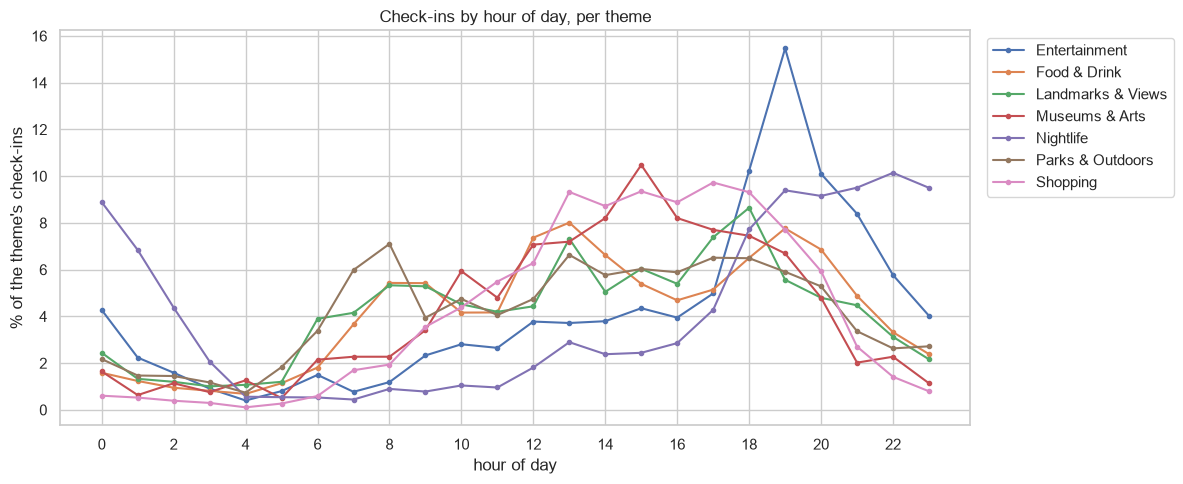

Busiest hour for each theme:
theme
Entertainment        19
Food & Drink         13
Landmarks & Views    18
Museums & Arts       15
Nightlife            22
Parks & Outdoors      8
Shopping             17
dtype: int32


In [13]:
hourly = pd.crosstab(fs["hour"], fs["theme"], normalize="columns") * 100

hourly.plot(figsize=(12, 5), marker="o", markersize=3)
plt.title("Check-ins by hour of day, per theme")
plt.xlabel("hour of day")
plt.ylabel("% of the theme's check-ins")
plt.xticks(range(0, 24, 2))
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG + "eda03_hourly_by_theme.png", dpi=150)
plt.show()

print("Busiest hour for each theme:")
print(hourly.idxmax())

**What we learned:** Each theme has its own busy time: Parks peak at **8 AM** (morning runs/walks), Food at **1 PM** (lunch),
Museums at **3 PM**, Shopping at **5 PM**, Landmarks at **6 PM**, Entertainment at **7 PM** (shows) and Nightlife at **10 PM**.

**How we use it:** the itinerary schedules each stop at a sensible hour for its theme.

### EDA 4: Day of week × hour heatmap (weekday vs weekend)

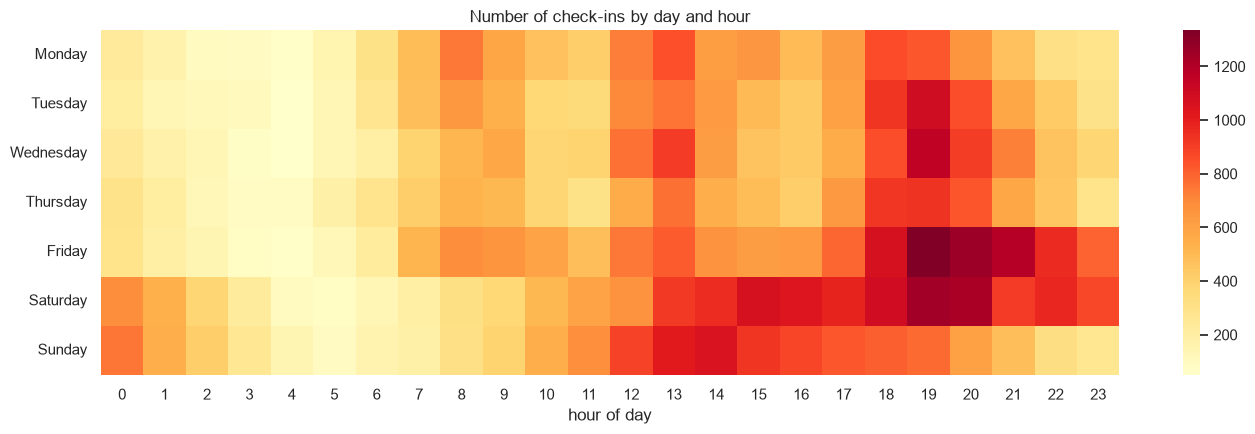

% of check-ins that happen on a weekend:
theme
Nightlife            41.2
Entertainment        36.7
Parks & Outdoors     33.9
Shopping             32.6
Museums & Arts       31.9
Food & Drink         30.2
Landmarks & Views    28.7
Name: is_weekend, dtype: float64


In [14]:
DAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

day_hour = pd.crosstab(fs["day_of_week"], fs["hour"]).reindex(DAY_ORDER)

plt.figure(figsize=(14, 4.5))
sns.heatmap(day_hour, cmap="YlOrRd")
plt.title("Number of check-ins by day and hour")
plt.xlabel("hour of day")
plt.ylabel("")
plt.tight_layout()
plt.savefig(FIG + "eda04_day_hour_heatmap.png", dpi=150)
plt.show()

# Weekends are 2 of 7 days (29%). A theme above 29% is more popular on weekends.
weekend_share = (fs.groupby("theme")["is_weekend"].mean() * 100).round(1).sort_values(ascending=False)
print("% of check-ins that happen on a weekend:")
print(weekend_share)

**What we learned:** Activity is highest in the afternoon and early evening, and weekend check-ins start later in the morning
and continue later at night. Weekends are 29% of the days, but **41% of Nightlife** and **37% of Entertainment**
check-ins happen on weekends, so these are more "weekend" activities.

**How we use it:** keep `is_weekend` as a feature and plan weekdays and weekends differently.

### EDA 5: The sunset effect: which themes are visited around sunset?
Share of each theme's check-ins in each light period.

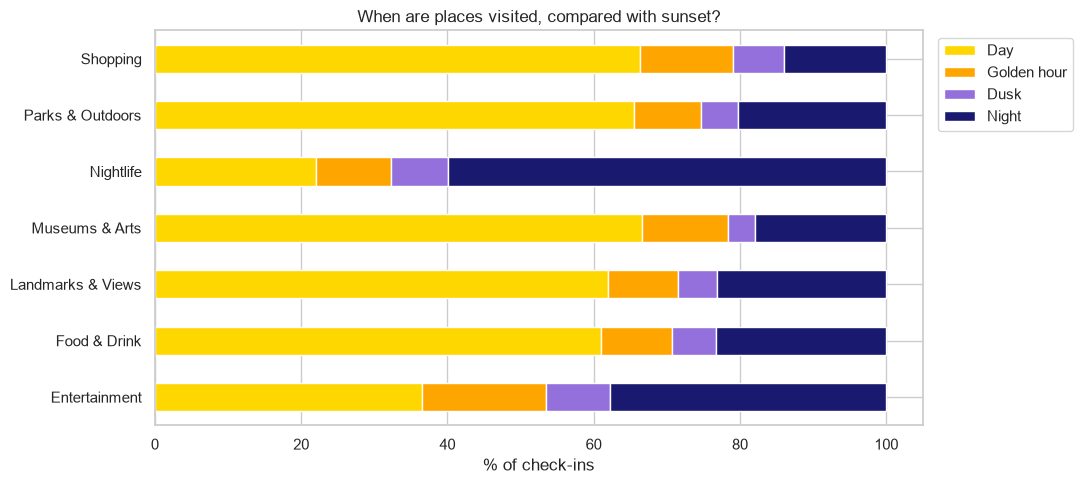

light_period,Day,Golden hour,Dusk,Night
theme,,,,
Entertainment,36.5,17.0,8.8,37.7
Food & Drink,61.0,9.8,6.0,23.3
Landmarks & Views,62.0,9.5,5.3,23.2
Museums & Arts,66.5,11.9,3.7,17.9
Nightlife,22.1,10.1,7.9,59.9
Parks & Outdoors,65.5,9.2,5.1,20.2
Shopping,66.4,12.7,7.0,14.0


In [15]:
period_order = ["Day", "Golden hour", "Dusk", "Night"]
light = pd.crosstab(fs["theme"], fs["light_period"], normalize="index")[period_order] * 100

light.plot(kind="barh", stacked=True, figsize=(11, 5), color=["gold", "orange", "mediumpurple", "midnightblue"])
plt.title("When are places visited, compared with sunset?")
plt.xlabel("% of check-ins")
plt.ylabel("")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG + "eda05_sunset.png", dpi=150)
plt.show()

light.round(1)

**What we learned:** Nightlife is mostly visited at **night (60%)** as expected. **Entertainment** has the biggest golden-hour
share (17%), followed by Shopping (13%) and Museums (12%). Parks and Landmarks are mostly visited during the day.

**How we use it:** `light_period` is kept as a feature so the app can suggest "golden hour" or "after dark" stops.

### EDA 6: Where is the activity? (map of check-ins)
Each dot is a check-in, placed by its latitude and longitude.

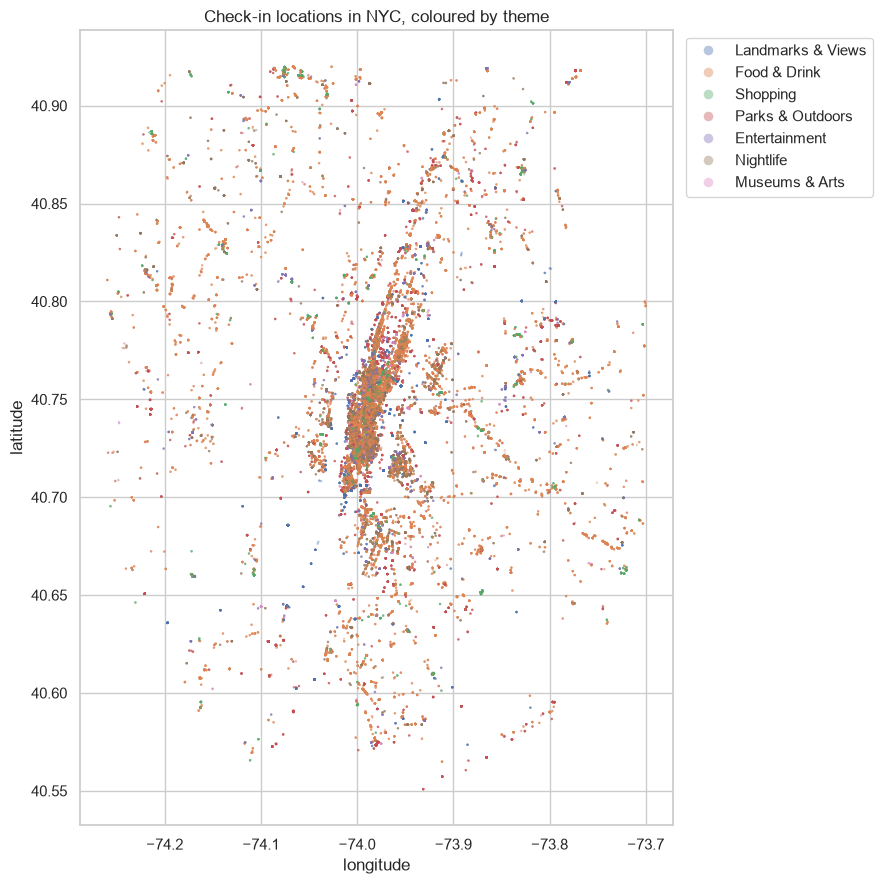

Share of check-ins in the Manhattan area: 67%


In [16]:
plt.figure(figsize=(9, 9))
sns.scatterplot(data=fs, x="longitude", y="latitude", hue="theme", s=3, alpha=0.4, linewidth=0)
plt.title("Check-in locations in NYC, coloured by theme")
plt.legend(markerscale=4, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG + "eda06_map.png", dpi=150)
plt.show()

# Rough borough check: Manhattan is roughly west of -73.93 and north of 40.70
manhattan = fs["longitude"].between(-74.02, -73.93) & fs["latitude"].between(40.70, 40.88)
print(f"Share of check-ins in the Manhattan area: {manhattan.mean():.0%}")

**What we learned:** Check-ins are very concentrated in **Manhattan (about 67%)**, especially Midtown and Lower Manhattan.
Brooklyn and Queens have smaller clusters.

**How we use it:** plan each day in one area so the traveller walks between nearby stops instead of crossing the city.

### EDA 7: Brooklyn Bridge: how crowded is it at each hour?
Average pedestrians per hour, weekdays vs weekends.

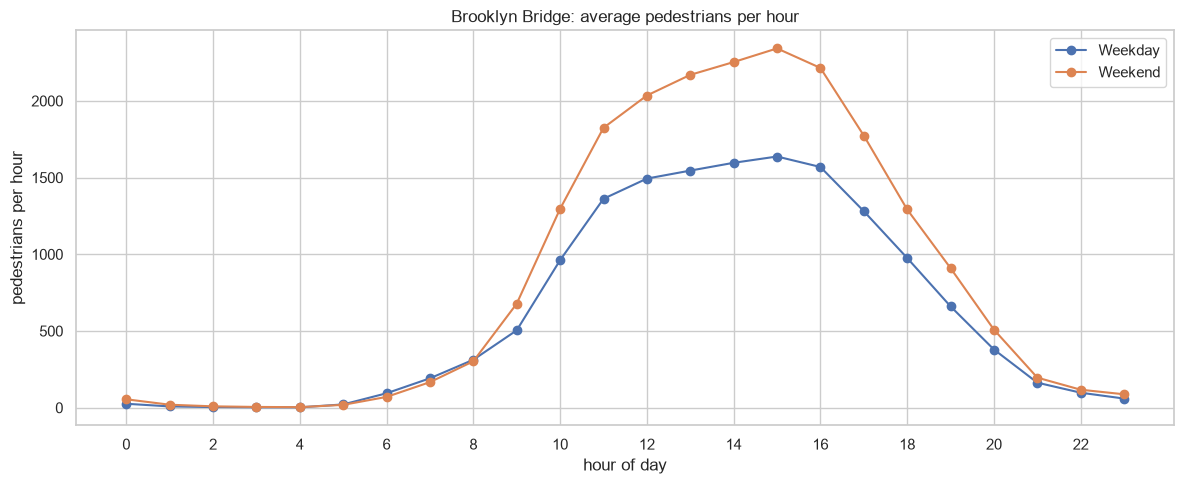

Busiest hour: {'Weekday': 15, 'Weekend': 15}
Average at 3 PM: {'Weekday': 1637.0, 'Weekend': 2342.0}
Average at 8 PM: {'Weekday': 379.0, 'Weekend': 509.0}


In [17]:
bridge_hourly = bridge.groupby(["hour", "is_weekend"])["pedestrians"].mean().unstack()
bridge_hourly.columns = ["Weekday", "Weekend"]

bridge_hourly.plot(figsize=(12, 5), marker="o")
plt.title("Brooklyn Bridge: average pedestrians per hour")
plt.xlabel("hour of day")
plt.ylabel("pedestrians per hour")
plt.xticks(range(0, 24, 2))
plt.tight_layout()
plt.savefig(FIG + "eda07_bridge_hourly.png", dpi=150)
plt.show()

print("Busiest hour:", bridge_hourly.idxmax().to_dict())
print("Average at 3 PM:", bridge_hourly.loc[15].round(0).to_dict())
print("Average at 8 PM:", bridge_hourly.loc[20].round(0).to_dict())

**What we learned:** The bridge is busiest at **3 PM** on both weekdays and weekends. Weekends are much busier
(about 2,340 vs 1,640 people per hour at 3 PM). At **8 PM** there are about **75–80% fewer people** than at 3 PM.

**How we use it:** the app can suggest visiting the bridge in the evening to avoid the crowds.

### EDA 8: Does the weather change the crowd?
Box plot of pedestrians per hour for each weather type. We use daytime hours only (10 AM – 7 PM),
otherwise night hours (always quiet) would hide the effect.

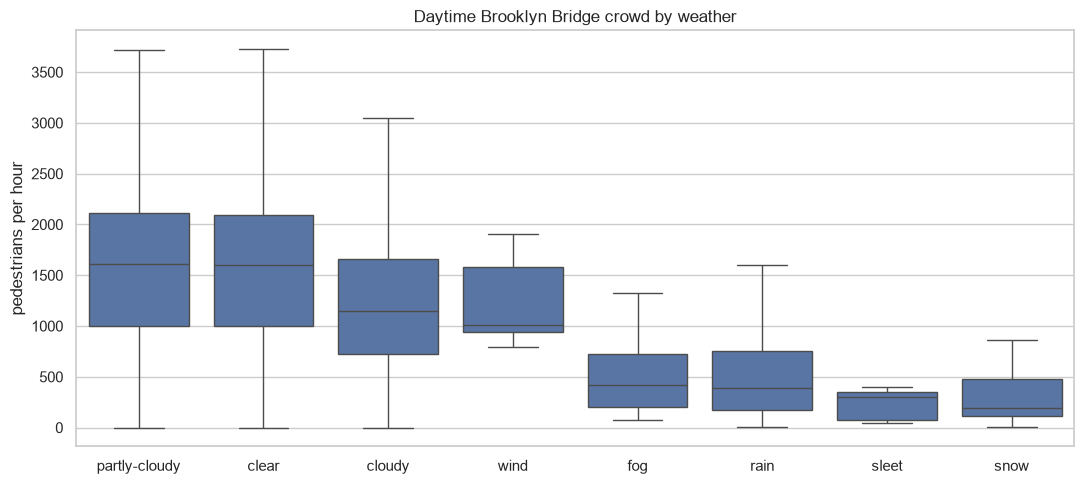

,count,mean,median
weather_summary,,,
partly-cloudy,2680,1587.0,1612.0
clear,2596,1567.0,1596.0
cloudy,940,1218.0,1146.0
wind,6,1236.0,1010.0
fog,28,499.0,416.0
rain,383,543.0,386.0
sleet,7,230.0,302.0
snow,50,335.0,191.0


In [18]:
daytime = bridge[bridge["hour"].between(10, 19)]

order = daytime.groupby("weather_summary")["pedestrians"].median().sort_values(ascending=False).index

plt.figure(figsize=(11, 5))
sns.boxplot(data=daytime, x="weather_summary", y="pedestrians", order=order, showfliers=False)
plt.title("Daytime Brooklyn Bridge crowd by weather")
plt.xlabel("")
plt.ylabel("pedestrians per hour")
plt.tight_layout()
plt.savefig(FIG + "eda08_weather.png", dpi=150)
plt.show()

daytime.groupby("weather_summary")["pedestrians"].agg(["count", "mean", "median"]).loc[order].round(0)

**What we learned:** Weather has a big effect. On clear or partly-cloudy days the median is about **1,600 people/hour**, on
rainy days about **390**, and on snowy days about **190**. (Wind, sleet and fog have very few hours, so those
boxes are less reliable.)

**How we use it:** on rainy days the app should swap outdoor stops (parks, views) for indoor ones (museums, food).

### EDA 9: Google ratings: distribution and differences between themes

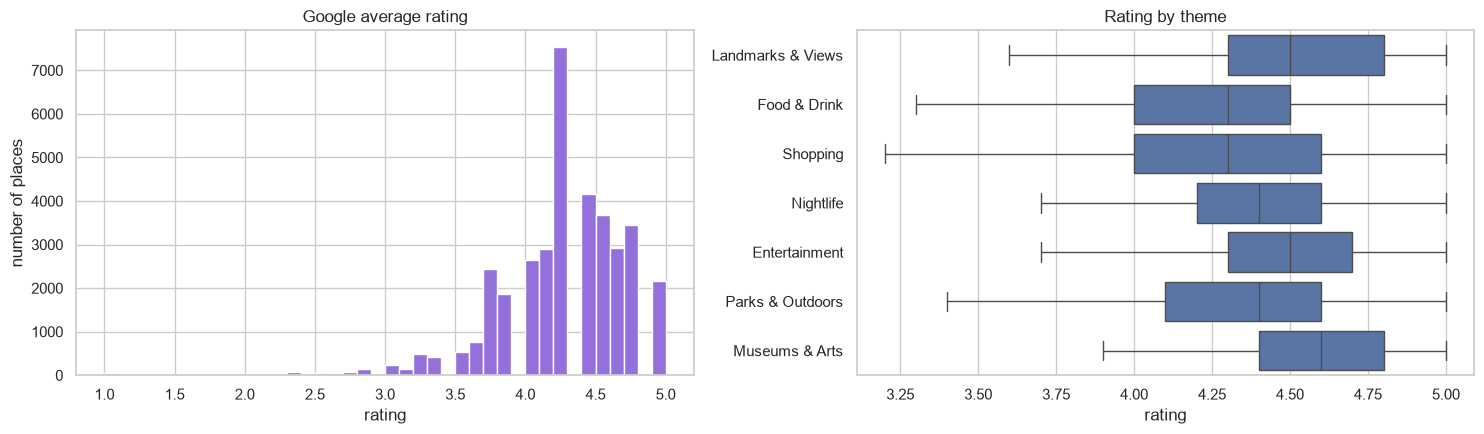

Places rated 4.0 or higher: 80%
theme
Museums & Arts       4.6
Landmarks & Views    4.5
Entertainment        4.5
Parks & Outdoors     4.4
Nightlife            4.4
Food & Drink         4.3
Shopping             4.3
Name: avg_rating, dtype: float64


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

axes[0].hist(google["avg_rating"], bins=40, color="mediumpurple")
axes[0].set_title("Google average rating")
axes[0].set_xlabel("rating")
axes[0].set_ylabel("number of places")

sns.boxplot(data=google, x="avg_rating", y="theme", ax=axes[1], showfliers=False)
axes[1].set_title("Rating by theme")
axes[1].set_xlabel("rating")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig(FIG + "eda09_ratings.png", dpi=150)
plt.show()

print(f"Places rated 4.0 or higher: {(google['avg_rating'] >= 4).mean():.0%}")
print(google.groupby("theme")["avg_rating"].median().sort_values(ascending=False))

**What we learned:** Ratings are bunched up high: **80% of places are rated 4.0 or more**, so the rating alone does not separate
places very well. Museums & Arts have the highest median rating (4.6) and Food & Shopping the lowest (4.3).

**How we use it:** use the rating together with the number of reviews, not the rating alone.

### EDA 10: Correlation between bridge features
Which numeric features move together with the number of pedestrians?

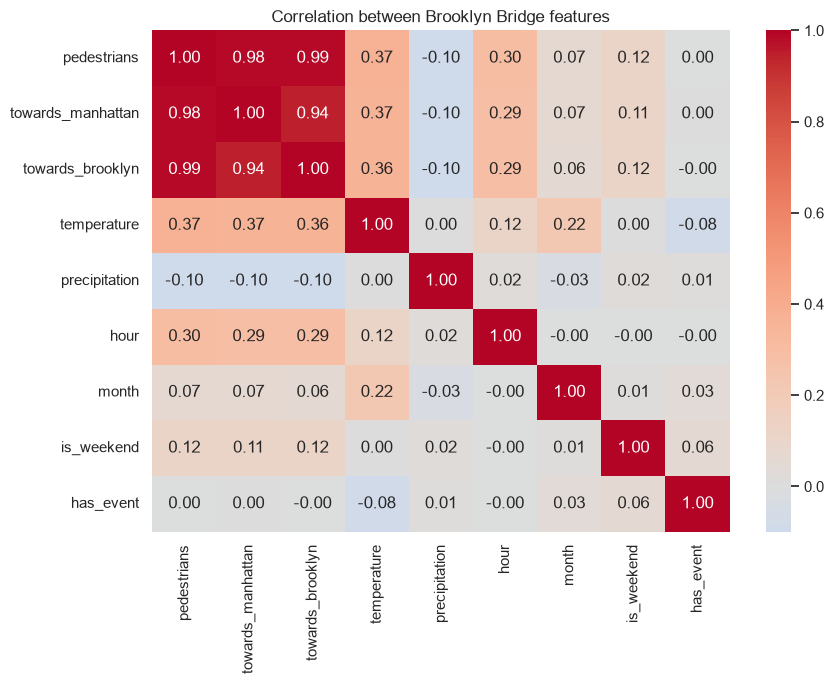

Correlation with pedestrians:
towards_brooklyn     0.99
towards_manhattan    0.98
temperature          0.37
hour                 0.30
is_weekend           0.12
month                0.07
has_event            0.00
precipitation       -0.10
Name: pedestrians, dtype: float64


In [20]:
numeric_columns = ["pedestrians", "towards_manhattan", "towards_brooklyn", "temperature", "precipitation", "hour", "month", "is_weekend", "has_event"]
corr = bridge[numeric_columns].astype(float).corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between Brooklyn Bridge features")
plt.tight_layout()
plt.savefig(FIG + "eda10_correlation.png", dpi=150)
plt.show()

print("Correlation with pedestrians:")
print(corr["pedestrians"].drop("pedestrians").sort_values(ascending=False).round(2))

**What we learned:** `towards_manhattan` and `towards_brooklyn` are almost the same as `pedestrians` (0.98–0.99) because they add up
to it, so they should **not** be used to predict crowds. **Temperature (0.37)** and **hour (0.30)** have the strongest
positive link with crowds, and precipitation has a small negative link (-0.10).

**How we use it:** to predict crowds we will use temperature, hour, weekend, month and precipitation.